# Mini-Project 4 — Rainfall Pattern & Crop Suitability Analyser

**Scenario.** An agricultural extension officer wants to compare rainfall regimes across regions and advise farmers which months suit which crops.

**Data.** Monthly rainfall (mm, Jan–Dec) for Kampala, Gulu and Mbarara from the brief (**illustrative**). The real-data extension (NASA POWER, 2014–2023) runs at the end once `python scripts/fetch_nasa_power.py` has downloaded the files.

Logic lives in `src/rainfall.py`: `Region`, `CropRule`, and the similarity functions.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from scipy.spatial.distance import cosine as scipy_cosine_distance

from src.rainfall import (MONTHS, CropRule, Region, classify_region, cosine_similarity, euclidean,
                          pairwise_matrix, parse_power_monthly, pearson)

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 1. The `Region` class

In [2]:
regions = [
    Region("Kampala", [120, 140, 180, 200, 220, 180, 90, 70, 60, 100, 110, 130]),
    Region("Gulu",    [8, 25, 75, 160, 190, 145, 170, 215, 175, 150, 60, 15]),
    Region("Mbarara", [70, 85, 120, 140, 90, 25, 20, 55, 100, 125, 120, 90]),
]
summary = pd.DataFrame([{"region": r.name, "annual total (mm)": r.annual_total(), "monthly mean (mm)": r.mean(),
                         "wettest": r.wettest_month(), "driest": r.driest_month(),
                         "CV": r.coefficient_of_variation()} for r in regions]).set_index("region")
display(summary)

,annual total (mm),monthly mean (mm),wettest,driest,CV
region,,,,,
Kampala,"1,600.000",133.333,May,Sep,0.388
Gulu,"1,388.000",115.667,Aug,Jan,0.642
Mbarara,"1,040.000",86.667,Apr,Jul,0.444


Kampala is the wettest overall (1,600 mm) and the most evenly spread (CV 0.39). Gulu's rain is the most concentrated in time (CV 0.64), with a near-rainless December–February. Mbarara is the driest (1,040 mm), and its two dips (January and June–July) are what separate its seasons.

## 2. Crop rules with cited thresholds
FAO gives crop water needs per **growing season** (Brouwer & Heibloem, 1986, *Irrigation Water Management Training Manual No. 3*, FAO, Ch. 2, Table 3): maize **500–800 mm** over a 125–180-day (grain) season, beans **300–500 mm** over 95–110 days (dry beans). I convert these to **monthly** windows by spreading the seasonal need over the season's length:

| Crop | Seasonal need (source) | Conversion | Monthly window |
|---|---|---|---|
| Maize | 500–800 mm, ~4–5 months (FAO) | 500/5 ≈ 100; 800/4 = 200 | **100–200 mm** |
| Beans | 300–500 mm, ~3–3.5 months (FAO) | 300/3.5 ≈ 85; 500/3 ≈ 165 | **85–165 mm** |
| Robusta coffee | best yields at 1,100–1,200 mm/yr in a Ugandan field study (Nakyagaba et al., 2024, *Int. J. Agronomy*); high-rainfall sites had the lowest yields and about double the pest/disease incidence | ≈ 95 mm/month average; I allow ±~55 mm for normal seasonality | **60–150 mm** |

These are **my conversions**, not published monthly thresholds. Crops need little water at sowing and most at flowering, so a flat monthly window is a simplification. Coffee is a perennial, so for coffee a "drought risk" month signals stress on standing trees rather than a planting window.

In [3]:
RULES = [
    CropRule("maize", 100, 200, source="Brouwer & Heibloem (1986), FAO Training Manual 3: 500–800 mm/season"),
    CropRule("beans", 85, 165, source="Brouwer & Heibloem (1986), FAO Training Manual 3: 300–500 mm/season"),
    CropRule("coffee", 60, 150, source="Nakyagaba et al. (2024), Int. J. Agronomy: optimum 1,100–1,200 mm/yr"),
]
for rule in RULES:
    print(rule)

labels = {r.name: classify_region(r, RULES) for r in regions}
for r in regions:
    display(pd.DataFrame(labels[r.name], index=MONTHS).T.rename_axis(r.name))

CropRule(crop='maize', min_mm=100, max_mm=200, source='Brouwer & Heibloem (1986), FAO Training Manual 3: 500–800 mm/season')
CropRule(crop='beans', min_mm=85, max_mm=165, source='Brouwer & Heibloem (1986), FAO Training Manual 3: 300–500 mm/season')
CropRule(crop='coffee', min_mm=60, max_mm=150, source='Nakyagaba et al. (2024), Int. J. Agronomy: optimum 1,100–1,200 mm/yr')


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Kampala,,,,,,,,,,,,
maize,Good for maize,Good for maize,Good for maize,Good for maize,Waterlogging risk,Good for maize,Drought risk,Drought risk,Drought risk,Good for maize,Good for maize,Good for maize
beans,Good for beans,Good for beans,Waterlogging risk,Waterlogging risk,Waterlogging risk,Waterlogging risk,Good for beans,Drought risk,Drought risk,Good for beans,Good for beans,Good for beans
coffee,Good for coffee,Good for coffee,Waterlogging risk,Waterlogging risk,Waterlogging risk,Waterlogging risk,Good for coffee,Good for coffee,Good for coffee,Good for coffee,Good for coffee,Good for coffee


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Gulu,,,,,,,,,,,,
maize,Drought risk,Drought risk,Drought risk,Good for maize,Good for maize,Good for maize,Good for maize,Waterlogging risk,Good for maize,Good for maize,Drought risk,Drought risk
beans,Drought risk,Drought risk,Drought risk,Good for beans,Waterlogging risk,Good for beans,Waterlogging risk,Waterlogging risk,Waterlogging risk,Good for beans,Drought risk,Drought risk
coffee,Drought risk,Drought risk,Good for coffee,Waterlogging risk,Waterlogging risk,Good for coffee,Waterlogging risk,Waterlogging risk,Waterlogging risk,Good for coffee,Good for coffee,Drought risk


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Mbarara,,,,,,,,,,,,
maize,Drought risk,Drought risk,Good for maize,Good for maize,Drought risk,Drought risk,Drought risk,Drought risk,Good for maize,Good for maize,Good for maize,Drought risk
beans,Drought risk,Good for beans,Good for beans,Good for beans,Good for beans,Drought risk,Drought risk,Drought risk,Good for beans,Good for beans,Good for beans,Good for beans
coffee,Good for coffee,Good for coffee,Good for coffee,Good for coffee,Good for coffee,Drought risk,Drought risk,Drought risk,Good for coffee,Good for coffee,Good for coffee,Good for coffee


## 3. Cosine similarity, done properly
The previous brief used `math.cos()`, which returns the cosine of an **angle in radians**: `math.cos(1600)` is just a number between −1 and 1 with no relation to how similar two rainfall series are. Cosine *similarity* is the cosine of the **angle between two vectors**, computed as dot(a, b) / (‖a‖·‖b‖).

In [4]:
k, g = regions[0].rainfall, regions[1].rainfall
mine = cosine_similarity(k, g)
scipy_val = 1 - scipy_cosine_distance(k, g)       # SciPy returns cosine *distance* = 1 − similarity
print(f"Kampala–Gulu cosine similarity: ours = {mine:.6f}, SciPy = {scipy_val:.6f}, equal: {np.isclose(mine, scipy_val)}")
print(f"By hand: dot = {np.dot(k, g):,.0f}, ‖K‖ = {np.linalg.norm(k):.2f}, ‖G‖ = {np.linalg.norm(g):.2f} → "
      f"{np.dot(k, g) / (np.linalg.norm(k) * np.linalg.norm(g)):.6f}")
print(f"The old (wrong) method, math.cos(sum K) = {np.cos(k.sum()):.4f} — meaningless")

Kampala–Gulu cosine similarity: ours = 0.786609, SciPy = 0.786609, equal: True
By hand: dot = 182,260, ‖K‖ = 492.75, ‖G‖ = 470.23 → 0.786609
The old (wrong) method, math.cos(sum K) = -0.5984 — meaningless


## 4. Three similarity/distance matrices

In [5]:
names = [r.name for r in regions]
for label, fn in [("Cosine similarity", cosine_similarity), ("Pearson correlation", pearson),
                  ("Euclidean distance (mm)", euclidean)]:
    display(pd.DataFrame(pairwise_matrix(regions, fn), index=names, columns=names).rename_axis(label))

wet_kampala = regions[0].rainfall * 2
print(f"Kampala vs a 'Kampala ×2' (twice as wet): cosine = {cosine_similarity(regions[0].rainfall, wet_kampala):.3f}, "
      f"Euclidean = {euclidean(regions[0].rainfall, wet_kampala):,.0f} mm")

,Kampala,Gulu,Mbarara
Cosine similarity,,,
Kampala,1.000,0.787,0.891
Gulu,0.787,1.000,0.749
Mbarara,0.891,0.749,1.000


,Kampala,Gulu,Mbarara
Pearson correlation,,,
Kampala,1.000,-0.066,0.209
Gulu,-0.066,1.000,-0.174
Mbarara,0.209,-0.174,1.000


,Kampala,Gulu,Mbarara
Euclidean distance (mm),,,
Kampala,0.000,315.268,250.400
Gulu,315.268,0.000,312.800
Mbarara,250.400,312.800,0.000


Kampala vs a 'Kampala ×2' (twice as wet): cosine = 1.000, Euclidean = 493 mm


**Why cosine can call a much wetter region "similar".** Cosine similarity compares only the *direction* of two vectors and ignores their length. Doubling every month of Kampala gives a cosine of exactly 1, "identical", even though the farmer would face twice the rain. On the real pairs the effect is just as misleading: all three cosines are high (0.75–0.89) because every month has positive rainfall, so all the vectors point into the same corner of 12-dimensional space. **Pearson** subtracts each region's mean first, so it compares the *timing* of wet and dry months. Its near-zero and negative values show that the three regimes actually peak at different times. **Euclidean** distance compares absolute amounts. The three measures answer different questions: overall share of rain per month, seasonal timing, and absolute difference.

## 5. Detecting rainy seasons with `scipy.signal.find_peaks`
Two practical issues: (1) the calendar is circular, so the series is tiled three times and only peaks in the middle copy are kept, to avoid missing a December peak; (2) a raw peak count over-splits seasons, since Gulu's small June dip creates a second "peak". A season boundary therefore requires a genuine **dry spell**: a month between two peaks that falls below the region's own monthly mean. Peaks without one are merged.

In [6]:
rows = []
for r in regions:
    rows.append({"region": r.name, "raw find_peaks months": [MONTHS[i] for i in r.rainfall_peaks()],
                 "season peaks after dry-spell check": [MONTHS[i] for i in r.rainy_seasons()],
                 "classification": r.modality()})
display(pd.DataFrame(rows).set_index("region"))

,raw find_peaks months,season peaks after dry-spell check,classification
region,,,
Kampala,"[May, Dec]","[May, Dec]",bimodal
Gulu,"[May, Aug]",[Aug],unimodal
Mbarara,"[Apr, Oct]","[Apr, Oct]",bimodal


**Check against Uganda's known climate zones.** The results match. The Lake Victoria basin (Kampala) and the south-west (Mbarara) are **bimodal**: long rains around March–May and short rains around September–November. Kampala's second peak appears in December here because the illustrative data keep it wet into the new year. Northern Uganda (Gulu) is **unimodal**, with one long wet season from about April to October. Its June dip is a known mid-season lull, not a dry season, which is why it should not be counted as two seasons. Without the dry-spell check, `find_peaks` alone would wrongly call Gulu bimodal.

## 6. Visualisation

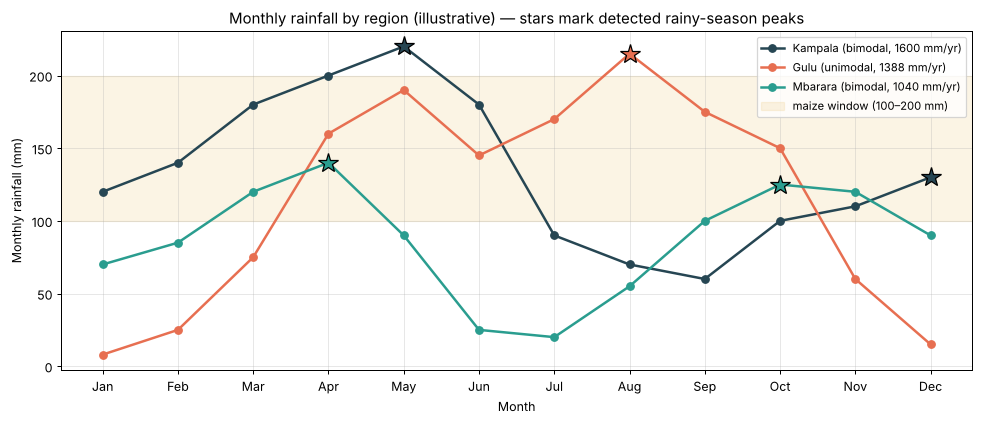

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.8))
style = {"Kampala": "#264653", "Gulu": "#e76f51", "Mbarara": "#2a9d8f"}
for r in regions:
    ax.plot(MONTHS, r.rainfall, "o-", lw=2, color=style[r.name], label=f"{r.name} ({r.modality()}, {r.annual_total():.0f} mm/yr)")
    seasons = r.rainy_seasons()
    ax.plot([MONTHS[i] for i in seasons], r.rainfall[seasons], "*", ms=16, color=style[r.name], mec="black")
ax.axhspan(100, 200, color="#e9c46a", alpha=0.18, label="maize window (100–200 mm)")
ax.set(ylabel="Monthly rainfall (mm)", xlabel="Month",
       title="Monthly rainfall by region (illustrative) — stars mark detected rainy-season peaks")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("figures/p4_rainfall_lines.png", dpi=150)
plt.show()

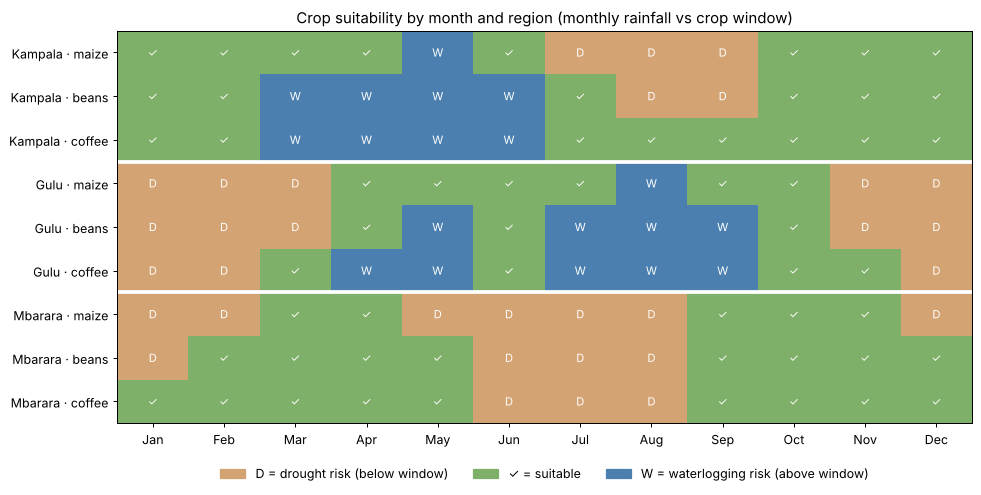

In [8]:
row_labels, grid = [], []
for r in regions:
    for rule in RULES:
        row_labels.append(f"{r.name} · {rule.crop}")
        grid.append([rule.score(v) for v in r.rainfall])
grid = np.array(grid)
cmap = ListedColormap(["#d4a373", "#7fb069", "#4a7fb0"])   # drought / suitable / waterlogging
fig, ax = plt.subplots(figsize=(11, 5.6))
ax.imshow(grid, cmap=cmap, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(12), MONTHS)
ax.set_yticks(range(len(row_labels)), row_labels)
symbols = {-1: "D", 0: "✓", 1: "W"}
for i in range(grid.shape[0]):
    for j in range(12):
        ax.text(j, i, symbols[grid[i, j]], ha="center", va="center", fontsize=9, color="white")
for y in (2.5, 5.5):
    ax.axhline(y, color="white", lw=3)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in cmap.colors]
ax.legend(handles, ["D = drought risk (below window)", "✓ = suitable", "W = waterlogging risk (above window)"],
          loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)
ax.set_title("Crop suitability by month and region (monthly rainfall vs crop window)")
fig.tight_layout()
fig.savefig("figures/p4_suitability_heatmap.png", dpi=150)
plt.show()

## 7. Advisory note — Mbarara farmers (≤ 200 words)

> **Plant beans twice a year; avoid relying on maize.**
>
> Mbarara has two rainy seasons, peaking in **April** and **October**, separated by a dry June–July and a drier January. In both seasons, monthly rain falls in the range that suits **beans** (about 85–165 mm a month). It rarely reaches the 100 mm or more that maize needs for four to five consecutive months: only March, April, September, October and November get there, and never five months in a row.
>
> **Season 1:** plant beans in **late February to early March**, as the rains establish, so the crop flowers in the wettest month (April). Harvest in **June**, when the dry weather helps drying and storage.
>
> **Season 2:** plant in **early September** and harvest in **December**.
>
> If you grow maize, use a **short-duration (early-maturing) variety**, plant at the very start of the season, and expect stress if rains end early. Do not plant in June or July: rain then is about 20–25 mm, far too little for any of these crops.
>
> *Based on long-term average rainfall. Check the seasonal forecast from UNMA each season before planting.*

## Extension — real NASA POWER rainfall, 2014–2023
Run `python scripts/fetch_nasa_power.py` (needs internet) to download monthly bias-corrected precipitation (`PRECTOTCORR`) for each town. The cell below parses the files with `parse_power_monthly`, converting mm/day to monthly totals, and draws box plots per month to show year-to-year variability. If the files are missing it explains what to run instead of failing, so *Restart & Run All* still works.

In [9]:
power_files = {r.name: Path(f"data/nasa_power_{r.name.lower()}.json") for r in regions}
if all(p.exists() for p in power_files.values()):
    real = {name: parse_power_monthly(json.loads(p.read_text())) for name, p in power_files.items()}
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
    for ax, (name, by_year) in zip(axes, real.items()):
        data = np.array(list(by_year.values()))                 # years × 12
        ax.boxplot([data[:, m][~np.isnan(data[:, m])] for m in range(12)])
        ax.set_xticks(range(1, 13), MONTHS)
        ax.plot(range(1, 13), np.nanmean(data, axis=0), "o-", color=style[name], label="10-yr mean")
        ax.set_title(f"{name}: {min(by_year)}–{max(by_year)} (NASA POWER)")
        ax.set_xlabel("Month")
        ax.grid(alpha=0.3)
        ax.legend()
        r_real = Region(name, np.nanmean(data, axis=0))
        print(f"{name}: real 10-yr mean annual = {r_real.annual_total():,.0f} mm, classified {r_real.modality()}; "
              f"mean inter-annual CV per month = {np.nanmean(np.nanstd(data, axis=0, ddof=1) / np.nanmean(data, axis=0)):.2f}")
    axes[0].set_ylabel("Monthly rainfall (mm)")
    fig.suptitle("Year-to-year variability of monthly rainfall, 2014–2023. Source: NASA LaRC POWER Project")
    fig.tight_layout()
    fig.savefig("figures/p4_nasa_power_boxplots.png", dpi=150)
    plt.show()
else:
    print("NASA POWER files not found. Run `python scripts/fetch_nasa_power.py` (internet needed), then re-run this notebook.")

NASA POWER files not found. Run `python scripts/fetch_nasa_power.py` (internet needed), then re-run this notebook.


## Findings & Limitations

**Findings.** The three regions represent Uganda's two main rainfall regimes, and the season detector recovers both correctly: Kampala and Mbarara are bimodal, Gulu unimodal. That only worked after adding a dry-spell rule on top of `find_peaks`, because peak counting alone mislabels Gulu's mid-season dip as a second season. The similarity analysis shows why the choice of measure matters. Cosine similarity rated every pair as fairly similar (0.75–0.89) only because all rainfall is positive. Pearson correlation, which compares timing, is close to zero or negative, so the regions' wet months do not line up. An extension officer comparing regions for planting dates should use correlation or the season analysis, not raw cosine similarity. On crop fit, Gulu's single long season suits one maize crop from April to October, though August's 215 mm briefly exceeds the window. Kampala's rain is plentiful but too heavy at its peak: May exceeds the maize window and March–June exceed the coffee window, which raises disease risk. Mbarara's two moderate seasons favour beans, planted twice a year, over long-season maize.

**Limitations.** The rainfall data are illustrative single-year climatologies. A long-term average hides the year-to-year variability that drives crop failure, which is exactly what the NASA POWER extension addresses. The crop windows are my conversions of FAO seasonal water needs into flat monthly ranges. They ignore crop growth stages, soil water-holding capacity, temperature and evapotranspiration (Mbarara's cooler highlands lose less water than Gulu's lowlands), and the coffee window draws on a single Ugandan field study. Monthly totals also hide the distribution of rain within a month: one storm and steady showers count the same. The peak-detection thresholds (10 mm prominence and the region's own mean as the dry-spell cut-off) are reasoned choices that should be tested on more stations.